# Modèle k-Nearest Neighbors (k-NN)

Ce notebook contient l'implémentation et l'évaluation du modèle k-Nearest Neighbors pour prédire l'attrition des employés.

## 1. Importation des bibliothèques

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve
import pickle

## 2. Chargement des données préparées

In [2]:
# Charger les données préparées
data = pd.read_csv('Data/prepared_data.csv')

# Séparer les caractéristiques et la cible
X = data.drop(columns=["Attrition", "EmployeeID"])
y = data['Attrition']

print(f"Shape des features: {X.shape}")
print(f"Shape de la cible: {y.shape}")
print(f"\nDistribution de la cible:\n{y.value_counts()}")

Shape des features: (4410, 45)
Shape de la cible: (4410,)

Distribution de la cible:
Attrition
0    3699
1     711
Name: count, dtype: int64


## 3. Séparation des données

In [3]:
# Séparation train/test (70/30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Taille ensemble d'entraînement: {X_train.shape[0]}")
print(f"Taille ensemble de test: {X_test.shape[0]}")

Taille ensemble d'entraînement: 3087
Taille ensemble de test: 1323


## 4. Entraînement du modèle k-Nearest Neighbors

L'algorithme k-Nearest Neighbors (k-NN) est un algorithme de classification basé sur la similarité. Il prédit la classe d'un point en fonction de la classe majoritaire de ses k plus proches voisins dans l'espace des features. C'est une méthode simple mais efficace qui ne fait aucune hypothèse sur la distribution des données.

In [4]:
# Initialisation et entraînement du modèle
# On utilise k=5 par défaut
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

print("Modèle k-NN entraîné avec succès!")

Modèle k-NN entraîné avec succès!


## 5. Prédictions

In [5]:
# Prédictions sur l'ensemble de test
y_pred = knn.predict(X_test)
y_proba = knn.predict_proba(X_test)[:, 1]

print("Prédictions effectuées!")

Prédictions effectuées!


## 6. Évaluation du modèle

### 6.1 Matrice de confusion

Matrice de Confusion (k-NN) :
 [[1032   83]
 [ 144   64]]


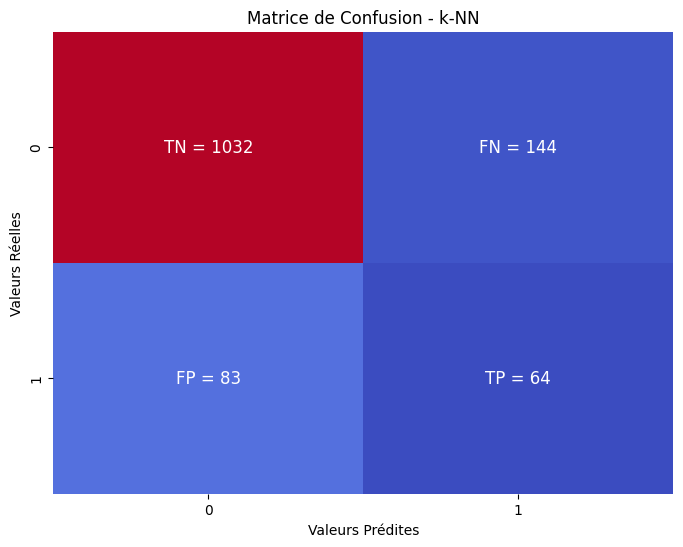

In [6]:
# Matrice de confusion
conf_matrix = confusion_matrix(y_test, y_pred)
print("Matrice de Confusion (k-NN) :\n", conf_matrix)

# Visualisation
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=False, fmt="d", cmap="coolwarm", cbar=False)

# Calcul des valeurs TP, TN, FP, FN
TN, FP, FN, TP = conf_matrix.ravel()

# Ajout des valeurs sur le graphique
plt.text(0.5, 0.5, f'TN = {TN}', ha='center', va='center', color='white', fontsize=12)
plt.text(0.5, 1.5, f'FP = {FP}', ha='center', va='center', color='white', fontsize=12)
plt.text(1.5, 0.5, f'FN = {FN}', ha='center', va='center', color='white', fontsize=12)
plt.text(1.5, 1.5, f'TP = {TP}', ha='center', va='center', color='white', fontsize=12)
plt.title("Matrice de Confusion - k-NN")
plt.ylabel('Valeurs Réelles')
plt.xlabel('Valeurs Prédites')
plt.show()

### 6.2 Rapport de classification

In [7]:
# Rapport de classification
class_report = classification_report(y_test, y_pred)
print("Rapport de Classification (k-NN) :\n", class_report)

Rapport de Classification (k-NN) :
               precision    recall  f1-score   support

           0       0.88      0.93      0.90      1115
           1       0.44      0.31      0.36       208

    accuracy                           0.83      1323
   macro avg       0.66      0.62      0.63      1323
weighted avg       0.81      0.83      0.82      1323



### 6.3 Courbe ROC et AUC

AUC Score: 0.8383


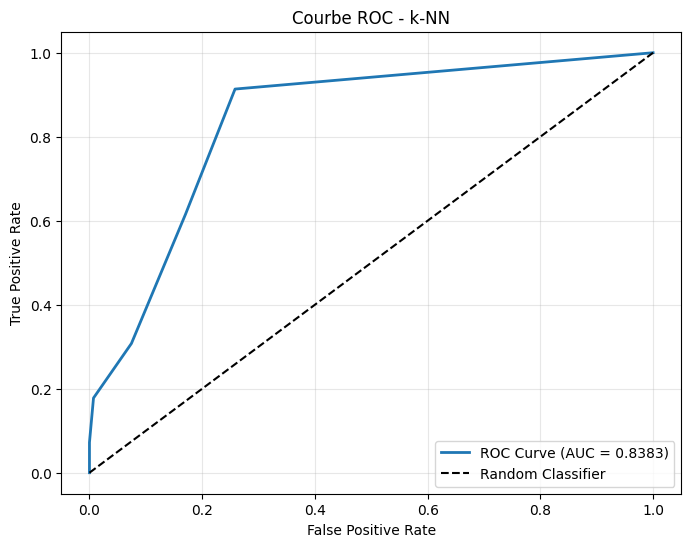

In [8]:
# Courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc_score = roc_auc_score(y_test, y_proba)

print(f"AUC Score: {auc_score:.4f}")

# Visualisation de la courbe ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc_score:.4f})', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Courbe ROC - k-NN')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7. Exploration de différentes valeurs de k

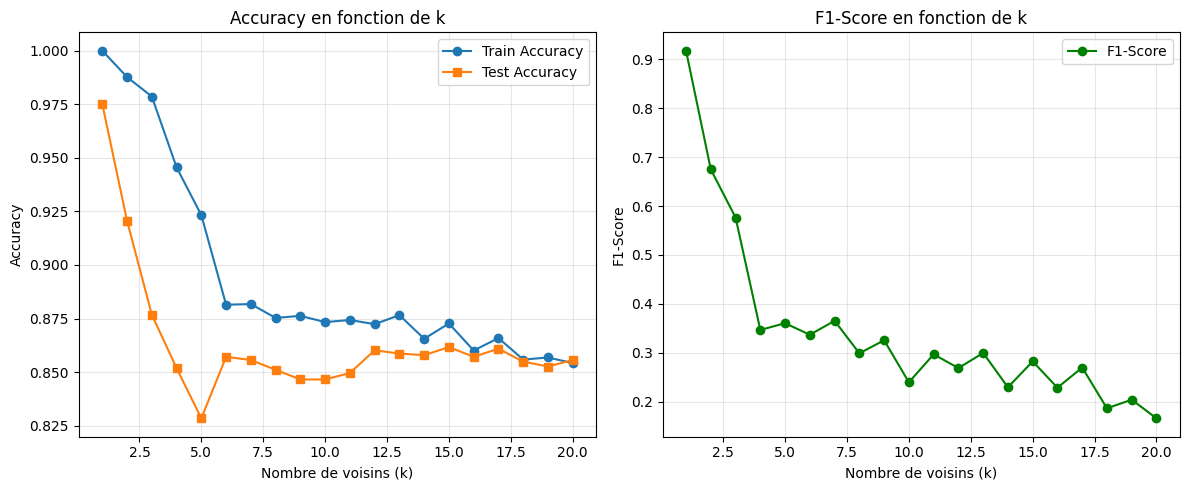

Meilleur k pour l'accuracy: 1 (accuracy: 0.9751)
Meilleur k pour le F1-score: 1 (F1: 0.9177)


In [9]:
# Tester différentes valeurs de k
from sklearn.metrics import accuracy_score, f1_score

k_values = range(1, 21)
train_scores = []
test_scores = []
f1_scores = []

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train, y_train)
    
    train_scores.append(accuracy_score(y_train, knn_temp.predict(X_train)))
    test_pred = knn_temp.predict(X_test)
    test_scores.append(accuracy_score(y_test, test_pred))
    f1_scores.append(f1_score(y_test, test_pred))

# Visualisation
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(k_values, train_scores, label='Train Accuracy', marker='o')
plt.plot(k_values, test_scores, label='Test Accuracy', marker='s')
plt.xlabel('Nombre de voisins (k)')
plt.ylabel('Accuracy')
plt.title('Accuracy en fonction de k')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(k_values, f1_scores, label='F1-Score', marker='o', color='green')
plt.xlabel('Nombre de voisins (k)')
plt.ylabel('F1-Score')
plt.title('F1-Score en fonction de k')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Trouver le meilleur k
best_k_accuracy = k_values[np.argmax(test_scores)]
best_k_f1 = k_values[np.argmax(f1_scores)]
print(f"Meilleur k pour l'accuracy: {best_k_accuracy} (accuracy: {max(test_scores):.4f})")
print(f"Meilleur k pour le F1-score: {best_k_f1} (F1: {max(f1_scores):.4f})")

## 8. Sauvegarde du modèle

In [10]:
# Sauvegarder le modèle
with open('Data/knn_model.pkl', 'wb') as f:
    pickle.dump(knn, f)

print("Modèle k-NN sauvegardé avec succès!")

Modèle k-NN sauvegardé avec succès!


## 9. Conclusion

Le modèle k-Nearest Neighbors a été entraîné et évalué avec succès. Les principales caractéristiques de ce modèle sont :
- Simple à comprendre et à implémenter
- Non paramétrique (ne fait pas d'hypothèses sur la distribution des données)
- Peut capturer des relations non linéaires complexes
- Sensible à la valeur de k et à l'échelle des features
- Temps de prédiction peut être plus long sur de grands ensembles de données

Le modèle sera comparé avec les autres algorithmes dans le notebook de comparaison.